In [5]:
# Cell 1 — Install dependencies
# Run once, then restart kernel
!pip install -q --upgrade transformers accelerate bitsandbytes peft datasets trl rouge-score sentencepiece huggingface_hub
print("✅ Done — RESTART KERNEL NOW, then run from Cell 2")

✅ Done — RESTART KERNEL NOW, then run from Cell 2


In [1]:
# Fix Windows cp1252 encoding bug in TRL's template loader
# Must run BEFORE any trl import

import pathlib

_orig_read_text = pathlib.Path.read_text

def _utf8_read_text(self, encoding=None, errors=None):
    """Force UTF-8 when no encoding is specified (fixes TRL on Windows)."""
    return _orig_read_text(self, encoding=encoding or 'utf-8', errors=errors)

pathlib.Path.read_text = _utf8_read_text
print("✅ Pathlib UTF-8 patch applied — TRL import will now work")

✅ Pathlib UTF-8 patch applied — TRL import will now work


In [2]:
# Cell 2 — Imports & Config

import os, sys
os.environ["PYTHONUTF8"] = "1"
os.environ["PYTHONIOENCODING"] = "utf-8"
import os, json, pickle, torch, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
warnings.filterwarnings('ignore')

# ── Fix HuggingFace download issues on slow/unstable connections ──────────
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "300"   # 5 min timeout per file
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

from transformers import (
    AutoTokenizer, AutoModelForCausalLM,
    AutoConfig, BitsAndBytesConfig
)
from peft import LoraConfig, get_peft_model, TaskType
from trl import SFTTrainer, SFTConfig
from datasets import Dataset
from rouge_score import rouge_scorer

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device  : {DEVICE}")
print(f"GPU     : {torch.cuda.get_device_name(0)}")
print(f"VRAM    : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
print(f"PyTorch : {torch.__version__}")

# ── CONFIG ────────────────────────────────────────────────────────────────
PAIRS_CSV  = "email_reply_pairs.csv"
OUT_DIR    = "presentation"
MODEL_DIR  = f"{OUT_DIR}/models/phi3_lora"
LOG_DIR    = f"{OUT_DIR}/results"
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(LOG_DIR,   exist_ok=True)

# Phi-3.5-mini — newer, more stable download, same 3.8B size, better quality
BASE_MODEL = "microsoft/Phi-3.5-mini-instruct"

# QLoRA (tuned for 8.6 GB VRAM on RTX 4060 Laptop)
LORA_R       = 16
LORA_ALPHA   = 32
LORA_DROPOUT = 0.05
TARGET_MODS  = ["qkv_proj", "o_proj", "gate_up_proj", "down_proj"]

# Training
MAX_SEQ_LEN  = 512
TRAIN_EPOCHS = 1        # ~2-3 hrs on RTX 4060
BATCH_SIZE   = 2
GRAD_ACCUM   = 8        # effective batch = 16
LR           = 2e-4
WARMUP_RATIO = 0.03
SAVE_STEPS   = 200

# Eval
EVAL_N      = 200
MAX_NEW_TOK = 150
# ──────────────────────────────────────────────────────────────────────────
print("\nConfig loaded ✅")

Device  : cuda
GPU     : NVIDIA GeForce RTX 4060 Laptop GPU
VRAM    : 8.6 GB
PyTorch : 2.7.1+cu118

Config loaded ✅


In [3]:
# Cell 3 — Load & format dataset
df = pd.read_csv(PAIRS_CSV)
print(f"Total pairs : {len(df):,}")

def format_sample(email_body: str, reply_body: str) -> str:
    """
    Phi-3.5 chat format:
      <|user|>\n{prompt}<|end|>\n<|assistant|>\n{reply}<|end|>
    """
    email_body = str(email_body).strip()[:800]
    reply_body = str(reply_body).strip()[:400]
    return (
        f"<|user|>\n"
        f"You are an email assistant. Write a professional reply "
        f"to the following email.\n\nEmail:\n{email_body}\n"
        f"<|end|>\n"
        f"<|assistant|>\n"
        f"{reply_body}"
        f"<|end|>"
    )

df['text'] = df.apply(
    lambda r: format_sample(r['email_body'], r['reply_body']), axis=1
)

val_size   = min(2000, int(len(df) * 0.1))
train_size = len(df) - val_size

df_train = df.iloc[:train_size].reset_index(drop=True)
df_val   = df.iloc[train_size:].reset_index(drop=True)

ds_train = Dataset.from_pandas(df_train[['text']])
ds_val   = Dataset.from_pandas(df_val[['text']])

print(f"Train samples : {len(ds_train):,}")
print(f"Val samples   : {len(ds_val):,}")
print(f"\nFormatted sample preview:\n{'-'*50}")
print(df['text'].iloc[0][:500])
print('-'*50)

Total pairs : 48,184
Train samples : 46,184
Val samples   : 2,000

Formatted sample preview:
--------------------------------------------------
<|user|>
You are an email assistant. Write a professional reply to the following email.

Email:
Time is running very short. Is your company prepared for Etag 1.7? These are the minimum REQUIRED steps that must be completed prior to March 6, 2002:

---------------------------

(1) All entities must update the NERC Registry at http://www.tsin.com.

(1a) CA's and TP's must designate PORs and PODs that are valid on tags.

(1b) PSE's must designate associated scheduling PORs and PODs. See http://www.
--------------------------------------------------


In [4]:
# Cell 4 — Load Phi-3.5-mini in 4-bit (QLoRA)
# ── Fix 1: clear stale cached model files that cause rope_scaling KeyError ─
import shutil
stale_cache = os.path.expanduser(
    r"~\.cache\huggingface\modules\transformers_modules\microsoft"
)
if os.path.exists(stale_cache):
    shutil.rmtree(stale_cache)
    print(f"Cleared stale model cache → {stale_cache}")

print(f"Loading {BASE_MODEL} in 4-bit...")
print("First run downloads ~2.4 GB. If it times out, re-run this cell.\n")

# ── 4-bit quantization config ──────────────────────────────────────────────
bnb_config = BitsAndBytesConfig(
    load_in_4bit              = True,
    bnb_4bit_quant_type       = "nf4",
    bnb_4bit_compute_dtype    = torch.float16,
    bnb_4bit_use_double_quant = True,
)

# ── Tokenizer ─────────────────────────────────────────────────────────────
tokenizer = AutoTokenizer.from_pretrained(
    BASE_MODEL,
    trust_remote_code = True,
    padding_side      = "right",
)
tokenizer.pad_token = tokenizer.eos_token
print("✅ Tokenizer loaded")

# ── Fix 2: patch rope_scaling before building model ────────────────────────
config = AutoConfig.from_pretrained(
    BASE_MODEL,
    trust_remote_code = True,
)
if hasattr(config, "rope_scaling") and isinstance(config.rope_scaling, dict):
    print(f"rope_scaling before patch : {config.rope_scaling}")
    if "type" not in config.rope_scaling:
        config.rope_scaling["type"] = "longrope"
        print(f"rope_scaling after patch  : {config.rope_scaling}")
    else:
        print("rope_scaling already has 'type' — no patch needed")

# ── Fix 3: use `dtype=` not `torch_dtype=` (deprecation fix) ─────────────
model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    config              = config,
    quantization_config = bnb_config,
    device_map          = "auto",
    trust_remote_code   = True,
    dtype               = torch.float16,    # ← fixed (was torch_dtype)
    attn_implementation = "eager",
)
model.config.use_cache = False  # required for gradient checkpointing

alloc = torch.cuda.memory_allocated() / 1e9
total = torch.cuda.get_device_properties(0).total_memory / 1e9
print(f"\n✅ Model loaded")
print(f"   VRAM used  : {alloc:.2f} GB / {total:.1f} GB")
print(f"   VRAM free  : {total - alloc:.2f} GB")
print(f"   Parameters : {sum(p.numel() for p in model.parameters())/1e9:.2f}B")

Cleared stale model cache → C:\Users\rohru\.cache\huggingface\modules\transformers_modules\microsoft
Loading microsoft/Phi-3.5-mini-instruct in 4-bit...
First run downloads ~2.4 GB. If it times out, re-run this cell.



[transformers] This model config has set a `rope_parameters['original_max_position_embeddings']` field, to be used together with `max_position_embeddings` to determine a scaling factor. Please set the `factor` field of `rope_parameters`with this ratio instead -- we recommend the use of this field over `original_max_position_embeddings`, as it is compatible with most model architectures.


✅ Tokenizer loaded
rope_scaling before patch : {'long_factor': [1.0800000429153442, 1.1100000143051147, 1.1399999856948853, 1.340000033378601, 1.5899999141693115, 1.600000023841858, 1.6200000047683716, 2.620000123977661, 3.2300000190734863, 3.2300000190734863, 4.789999961853027, 7.400000095367432, 7.700000286102295, 9.09000015258789, 12.199999809265137, 17.670000076293945, 24.46000099182129, 28.57000160217285, 30.420001983642578, 30.840002059936523, 32.590003967285156, 32.93000411987305, 42.320003509521484, 44.96000289916992, 50.340003967285156, 50.45000457763672, 57.55000305175781, 57.93000411987305, 58.21000289916992, 60.1400032043457, 62.61000442504883, 62.62000274658203, 62.71000289916992, 63.1400032043457, 63.1400032043457, 63.77000427246094, 63.93000411987305, 63.96000289916992, 63.970001220703125, 64.02999877929688, 64.06999969482422, 64.08000183105469, 64.12000274658203, 64.41000366210938, 64.4800033569336, 64.51000213623047, 64.52999877929688, 64.83999633789062], 'short_factor

`flash-attention` package not found, consider installing for better performance: No module named 'flash_attn'.
Current `flash-attention` does not support `window_size`. Either upgrade or use `attn_implementation='eager'`.
Loading weights: 100%|██████████| 195/195 [00:03<00:00, 50.42it/s]



✅ Model loaded
   VRAM used  : 2.26 GB / 8.6 GB
   VRAM free  : 6.32 GB
   Parameters : 2.01B


In [5]:
# Cell 5 — Apply LoRA adapters
print("Applying LoRA adapters...")

lora_config = LoraConfig(
    r              = LORA_R,
    lora_alpha     = LORA_ALPHA,
    lora_dropout   = LORA_DROPOUT,
    bias           = "none",
    task_type      = TaskType.CAUSAL_LM,
    target_modules = TARGET_MODS,
)

model = get_peft_model(model, lora_config)

trainable    = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())

print(f"\n✅ LoRA applied")
print(f"   Trainable params : {trainable:,}  ({100*trainable/total_params:.2f}% of total)")
print(f"   Frozen params    : {total_params - trainable:,}")
print(f"   LoRA rank        : {LORA_R}")
print(f"   Target modules   : {TARGET_MODS}")
model.print_trainable_parameters()

Applying LoRA adapters...

✅ LoRA applied
   Trainable params : 25,165,824  (1.24% of total)
   Frozen params    : 2,009,140,224
   LoRA rank        : 16
   Target modules   : ['qkv_proj', 'o_proj', 'gate_up_proj', 'down_proj']
trainable params: 25,165,824 || all params: 3,846,245,376 || trainable%: 0.6543


In [8]:
# Cell 6 — Fine-tune with SFTTrainer
print("Setting up SFTTrainer...")

sft_config = SFTConfig(
    output_dir                   = MODEL_DIR,
    num_train_epochs             = TRAIN_EPOCHS,
    per_device_train_batch_size  = BATCH_SIZE,
    per_device_eval_batch_size   = BATCH_SIZE,
    gradient_accumulation_steps  = GRAD_ACCUM,
    learning_rate                = LR,
    warmup_ratio                 = WARMUP_RATIO,
    lr_scheduler_type            = "cosine",
    bf16                          = True,
    logging_steps                = 50,
    eval_strategy                = "steps",
    eval_steps                   = SAVE_STEPS,
    save_steps                   = SAVE_STEPS,
    save_total_limit             = 2,
    load_best_model_at_end       = True,
    report_to                    = "none",
    max_length                   = MAX_SEQ_LEN,   # ← renamed from max_seq_length
    dataset_text_field           = "text",
    gradient_checkpointing       = True,
    dataloader_pin_memory        = False,
)

trainer = SFTTrainer(
    model            = model,
    args             = sft_config,
    train_dataset    = ds_train,
    eval_dataset     = ds_val,
    processing_class = tokenizer,
)

print(f"\nStarting fine-tuning...")
print(f"  Train samples  : {len(ds_train):,}")
print(f"  Epochs         : {TRAIN_EPOCHS}")
print(f"  Effective batch: {BATCH_SIZE * GRAD_ACCUM}")
print(f"  Max seq len    : {MAX_SEQ_LEN} tokens")
print(f"  Est. time      : 2–3 hrs on RTX 4060\n")

train_result = trainer.train()

print("\n✅ Fine-tuning complete!")
print(f"   Train loss : {train_result.training_loss:.4f}")
print(f"   Runtime    : {train_result.metrics['train_runtime']/3600:.2f} hrs")

# ── Save LoRA adapter (~50 MB) ─────────────────────────────────────────────
trainer.save_model(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)

train_meta = {
    "base_model"    : BASE_MODEL,
    "lora_r"        : LORA_R,
    "lora_alpha"    : LORA_ALPHA,
    "target_mods"   : TARGET_MODS,
    "max_seq_len"   : MAX_SEQ_LEN,
    "epochs"        : TRAIN_EPOCHS,
    "train_loss"    : train_result.training_loss,
    "runtime_hrs"   : train_result.metrics['train_runtime'] / 3600,
    "train_samples" : len(ds_train),
}
with open(f"{MODEL_DIR}/train_meta.json", "w") as f:
    json.dump(train_meta, f, indent=2)

print(f"\n✅ LoRA adapter + metadata saved → {MODEL_DIR}/")

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Setting up SFTTrainer...


Tokenizing eval dataset: 100%|██████████| 2000/2000 [00:00<00:00, 3251.95 examples/s]



Starting fine-tuning...
  Train samples  : 46,184
  Epochs         : 1
  Effective batch: 16
  Max seq len    : 512 tokens
  Est. time      : 2–3 hrs on RTX 4060



Step,Training Loss,Validation Loss
200,5.960932,5.855302
400,5.112521,5.301353
600,4.901342,5.166862
800,6.449157,6.555654
1000,6.262025,6.517716
1200,6.233409,6.499073
1400,6.142070,6.421415
1600,6.182706,6.330391
1800,6.069238,6.342836
2000,6.064101,6.350855



✅ Fine-tuning complete!
   Train loss : 6.0637
   Runtime    : 7.83 hrs

✅ LoRA adapter + metadata saved → presentation/models/phi3_lora/


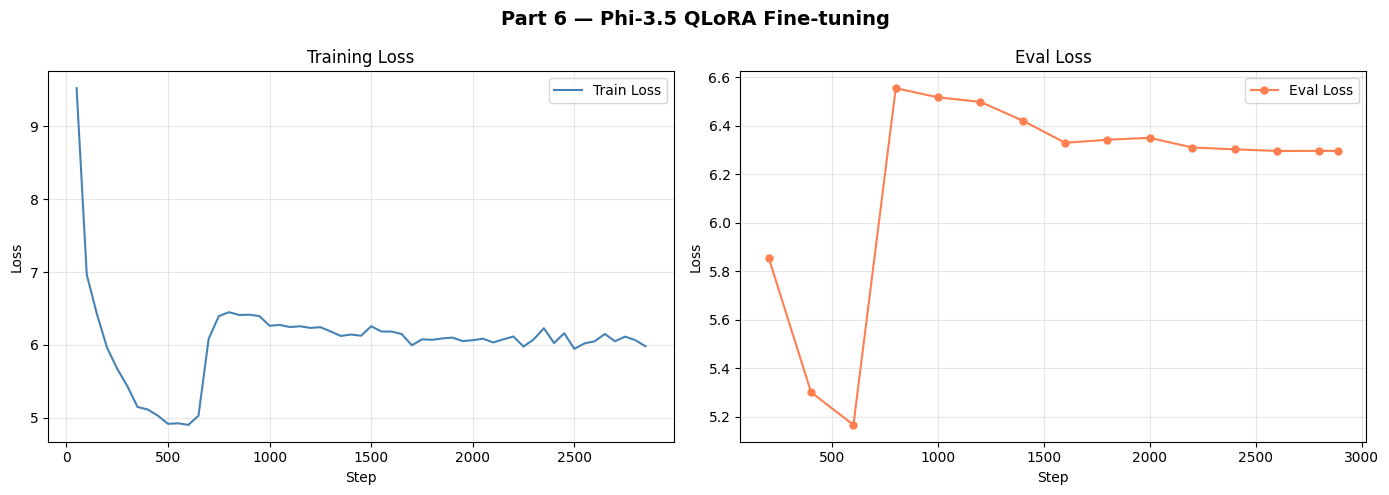

✅ Training curves saved


In [9]:
# Cell 7 — Training & Eval Loss Curves
log_history = trainer.state.log_history
train_logs  = [x for x in log_history if 'loss'      in x and 'eval_loss' not in x]
eval_logs   = [x for x in log_history if 'eval_loss' in x]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Part 6 — Phi-3.5 QLoRA Fine-tuning", fontsize=14, fontweight='bold')

if train_logs:
    steps  = [x['step'] for x in train_logs]
    losses = [x['loss']  for x in train_logs]
    axes[0].plot(steps, losses, color='steelblue', linewidth=1.5, label='Train Loss')
    axes[0].set_title("Training Loss")
    axes[0].set_xlabel("Step")
    axes[0].set_ylabel("Loss")
    axes[0].legend(); axes[0].grid(alpha=0.3)

if eval_logs:
    e_steps  = [x['step']      for x in eval_logs]
    e_losses = [x['eval_loss'] for x in eval_logs]
    axes[1].plot(e_steps, e_losses, color='coral', linewidth=1.5,
                 marker='o', markersize=5, label='Eval Loss')
    axes[1].set_title("Eval Loss")
    axes[1].set_xlabel("Step")
    axes[1].set_ylabel("Loss")
    axes[1].legend(); axes[1].grid(alpha=0.3)
else:
    axes[1].text(0.5, 0.5, 'No eval logs\n(eval_steps not reached)',
                ha='center', va='center', transform=axes[1].transAxes)

plt.tight_layout()
plt.savefig(f"{LOG_DIR}/part6_training_curve.png", dpi=150)
plt.show()

with open(f"{LOG_DIR}/part6_log_history.json", "w") as f:
    json.dump(log_history, f, indent=2)
print("✅ Training curves saved")

In [3]:
# ============================================================
# Cell 8 — COMPLETE SELF-CONTAINED (all fixes applied)
# Safe to run after kernel restart, no prior cells needed
# ============================================================

# ── UTF-8 patch for TRL on Windows (must be before any trl import) ─────────
import pathlib
_orig = pathlib.Path.read_text
def _utf8(self, encoding=None, errors=None):
    return _orig(self, encoding=encoding or 'utf-8', errors=errors)
pathlib.Path.read_text = _utf8

import os, sys, json, gc, shutil, torch, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
warnings.filterwarnings('ignore')

os.environ["PYTHONUTF8"]            = "1"
os.environ["PYTHONIOENCODING"]      = "utf-8"
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "300"
os.environ["TOKENIZERS_PARALLELISM"]  = "false"

from transformers import (
    AutoModelForCausalLM, AutoTokenizer,
    BitsAndBytesConfig
)
from peft import PeftModel
from rouge_score import rouge_scorer

# ── CONFIG ─────────────────────────────────────────────────────────────────
PAIRS_CSV   = "email_reply_pairs.csv"
OUT_DIR     = "presentation"
MODEL_DIR   = f"{OUT_DIR}/models/phi3_lora"
LOG_DIR     = f"{OUT_DIR}/results"
BASE_MODEL  = "microsoft/Phi-3.5-mini-instruct"
DEVICE      = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MAX_SEQ_LEN = 512
MAX_NEW_TOK = 150
EVAL_N      = 200

print(f"Device : {DEVICE}")
print(f"GPU    : {torch.cuda.get_device_name(0)}")
print(f"VRAM   : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")

# ── Load dataset ────────────────────────────────────────────────────────────
df       = pd.read_csv(PAIRS_CSV)
val_size = min(2000, int(len(df) * 0.1))
df_val   = df.iloc[len(df) - val_size:].reset_index(drop=True)
eval_df  = df_val.iloc[:EVAL_N].reset_index(drop=True)
print(f"\nEval samples : {len(eval_df)}")

# ── Clear stale remote code cache (fixes seen_tokens AttributeError) ────────
stale = os.path.expanduser(
    r"~\.cache\huggingface\modules\transformers_modules\microsoft"
)
if os.path.exists(stale):
    shutil.rmtree(stale)
    print("Cleared stale HF remote code cache")

# ── Clear GPU memory ────────────────────────────────────────────────────────
gc.collect()
torch.cuda.empty_cache()

# ── Load base model in 4-bit — trust_remote_code=False (fixes seen_tokens) ─
print(f"\nLoading base model: {BASE_MODEL}")
print("(uses local transformers Phi3 implementation — no remote code)\n")

bnb_config = BitsAndBytesConfig(
    load_in_4bit              = True,
    bnb_4bit_quant_type       = "nf4",
    bnb_4bit_compute_dtype    = torch.bfloat16,
    bnb_4bit_use_double_quant = True,
)

base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    quantization_config = bnb_config,
    device_map          = "auto",
    trust_remote_code   = False,   # KEY: use transformers built-in, not cached remote
    dtype               = torch.bfloat16,
    attn_implementation = "eager",
    low_cpu_mem_usage   = True,
)

# ── Load saved LoRA adapter ─────────────────────────────────────────────────
print(f"Loading LoRA adapter from: {MODEL_DIR}")
model     = PeftModel.from_pretrained(base_model, MODEL_DIR)
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_DIR,
    trust_remote_code = False,
)
tokenizer.pad_token = tokenizer.eos_token
model.eval()

alloc = torch.cuda.memory_allocated() / 1e9
total = torch.cuda.get_device_properties(0).total_memory / 1e9
print(f"\n✅ Fine-tuned model ready")
print(f"   VRAM used : {alloc:.2f} GB / {total:.1f} GB")

# ── Reply generator ─────────────────────────────────────────────────────────
def generate_reply(email_text, mdl, tok, max_new_tokens=MAX_NEW_TOK):
    prompt = (
        f"<|user|>\n"
        f"You are an email assistant. Write a professional reply "
        f"to the following email.\n\nEmail:\n{str(email_text).strip()[:600]}\n"
        f"<|end|>\n<|assistant|>\n"
    )
    inputs = tok(
        prompt,
        return_tensors = "pt",
        truncation     = True,
        max_length     = MAX_SEQ_LEN,
    ).to(DEVICE)

    with torch.no_grad():
        out = mdl.generate(
            **inputs,
            max_new_tokens  = max_new_tokens,
            do_sample       = False,
            pad_token_id    = tok.eos_token_id,
            eos_token_id    = tok.eos_token_id,
            use_cache       = True,
            past_key_values = None,   # fresh cache each call
        )

    gen = out[0][inputs['input_ids'].shape[1]:]
    return tok.decode(gen, skip_special_tokens=True).strip()

# ── ROUGE evaluation ─────────────────────────────────────────────────────────
rouge  = rouge_scorer.RougeScorer(['rouge1','rouge2','rougeL'], use_stemmer=True)
ft_r1, ft_r2, ft_rL = [], [], []
errors = 0

print(f"\nEvaluating {EVAL_N} samples...")

for _, row in tqdm(eval_df.iterrows(), total=len(eval_df), desc="ROUGE eval"):
    email = str(row['email_body'])
    ref   = str(row['reply_body'])

    if not email.strip() or not ref.strip():
        errors += 1
        continue

    pred = generate_reply(email, model, tokenizer)

    if not pred.strip():
        pred = "Thank you for your email. I will follow up shortly."

    sc = rouge.score(ref, pred)
    ft_r1.append(sc['rouge1'].fmeasure)
    ft_r2.append(sc['rouge2'].fmeasure)
    ft_rL.append(sc['rougeL'].fmeasure)

print(f"\n{'='*50}")
print(f"   Fine-tuned Phi-3.5 — ROUGE Results")
print(f"{'='*50}")
print(f"  ROUGE-1  : {np.mean(ft_r1):.4f}")
print(f"  ROUGE-2  : {np.mean(ft_r2):.4f}")
print(f"  ROUGE-L  : {np.mean(ft_rL):.4f}")
print(f"  Evaluated: {len(ft_r1)}  |  Skipped: {errors}")
print(f"{'='*50}")

# ── Save ROUGE scores so Cell 9 can use them ────────────────────────────────
os.makedirs(LOG_DIR, exist_ok=True)
rouge_scores_tmp = {
    "ft_r1": [float(x) for x in ft_r1],
    "ft_r2": [float(x) for x in ft_r2],
    "ft_rL": [float(x) for x in ft_rL],
}
with open(f"{LOG_DIR}/part6_rouge_tmp.json", "w") as f:
    json.dump(rouge_scores_tmp, f)
print(f"\n✅ Scores cached → {LOG_DIR}/part6_rouge_tmp.json  (used by Cell 9)")


Device : cuda
GPU    : NVIDIA GeForce RTX 4060 Laptop GPU
VRAM   : 8.6 GB

Eval samples : 200
Cleared stale HF remote code cache

Loading base model: microsoft/Phi-3.5-mini-instruct
(uses local transformers Phi3 implementation — no remote code)



Loading weights: 100%|██████████| 195/195 [00:02<00:00, 71.61it/s]


Loading LoRA adapter from: presentation/models/phi3_lora

✅ Fine-tuned model ready
   VRAM used : 4.73 GB / 8.6 GB

Evaluating 200 samples...


ROUGE eval: 100%|██████████| 200/200 [46:35<00:00, 13.98s/it]


   Fine-tuned Phi-3.5 — ROUGE Results
  ROUGE-1  : 0.1722
  ROUGE-2  : 0.0244
  ROUGE-L  : 0.1017
  Evaluated: 200  |  Skipped: 0

✅ Scores cached → presentation/results/part6_rouge_tmp.json  (used by Cell 9)



   AUTOMAIL — COMPLETE MODEL COMPARISON
  Model                            Task         Metric          Score
  -----------------------------------------------------------------------
  SBERT Baseline (Part 4)          Retrieval    Recall@1       0.1055
  SBERT Baseline (Part 4)          Retrieval    MRR            0.1695
  GNN GraphSAGE (Part 4)           Retrieval    Recall@1       0.0035  ← worse than SBERT
  GNN GraphSAGE (Part 4)           Retrieval    MRR            0.0133
  -----------------------------------------------------------------------
  MMR Retrieval (Part 5)           Generation   ROUGE-1        0.4122
  MMR Retrieval (Part 5)           Generation   ROUGE-2        0.3054
  MMR Retrieval (Part 5)           Generation   ROUGE-L        0.3691
  -----------------------------------------------------------------------
  Phi-3.5 Fine-tuned (Part 6)      Generation   ROUGE-1        0.1722
  Phi-3.5 Fine-tuned (Part 6)      Generation   ROUGE-2        0.0244
  Phi-3.5 Fine-tu

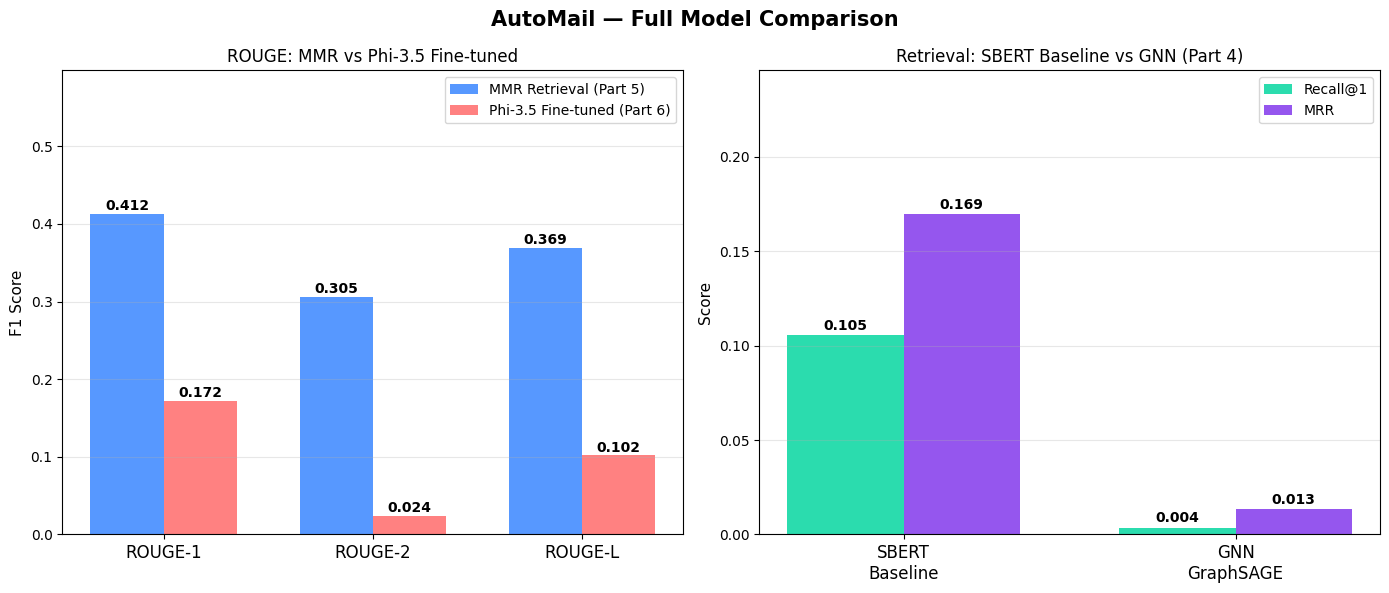

✅ Chart saved → presentation/results/part6_comparison.png
✅ Results saved → presentation/results/part6_results.json

🏁 Part 6 COMPLETE — Ready for Part 7: Final unified demo!


In [4]:
# ============================================================
# Cell 9 — COMPLETE SELF-CONTAINED COMPARISON + SAVE
# Can run right after Cell 8 or independently (loads from JSON)
# ============================================================

import os, json, warnings
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

LOG_DIR = "presentation/results"
MODEL_DIR = "presentation/models/phi3_lora"
BASE_MODEL = "microsoft/Phi-3.5-mini-instruct"

# ── Load Part 4 GNN results ─────────────────────────────────────────────────
with open(f"{LOG_DIR}/part4_gnn_results.json") as f:
    p4 = json.load(f)

# ── Load Part 5 MMR results ─────────────────────────────────────────────────
with open(f"{LOG_DIR}/part5_results.json") as f:
    p5 = json.load(f)

# ── Load Part 6 ROUGE scores (saved by Cell 8) ──────────────────────────────
with open(f"{LOG_DIR}/part6_rouge_tmp.json") as f:
    tmp = json.load(f)

ft_r1 = tmp["ft_r1"]
ft_r2 = tmp["ft_r2"]
ft_rL = tmp["ft_rL"]

# ── Collect all scores ──────────────────────────────────────────────────────
mmr_r1 = p5['metrics']['rouge1_best']
mmr_r2 = p5['metrics']['rouge2_best']
mmr_rL = p5['metrics']['rougeL_best']

phi_r1 = float(np.mean(ft_r1))
phi_r2 = float(np.mean(ft_r2))
phi_rL = float(np.mean(ft_rL))

gnn_base_r1  = p4['baseline_sbert']['recall@1']
gnn_base_mrr = p4['baseline_sbert']['mrr']
gnn_r1       = p4['gnn']['recall@1']
gnn_mrr      = p4['gnn']['mrr']

# ── Print full comparison table ─────────────────────────────────────────────
print("\n" + "="*75)
print("   AUTOMAIL — COMPLETE MODEL COMPARISON")
print("="*75)
print(f"  {'Model':<32} {'Task':<12} {'Metric':<12} {'Score':>8}")
print(f"  {'-'*71}")
print(f"  {'SBERT Baseline (Part 4)':<32} {'Retrieval':<12} {'Recall@1':<12} {gnn_base_r1:>8.4f}")
print(f"  {'SBERT Baseline (Part 4)':<32} {'Retrieval':<12} {'MRR':<12} {gnn_base_mrr:>8.4f}")
print(f"  {'GNN GraphSAGE (Part 4)':<32} {'Retrieval':<12} {'Recall@1':<12} {gnn_r1:>8.4f}  ← worse than SBERT")
print(f"  {'GNN GraphSAGE (Part 4)':<32} {'Retrieval':<12} {'MRR':<12} {gnn_mrr:>8.4f}")
print(f"  {'-'*71}")
print(f"  {'MMR Retrieval (Part 5)':<32} {'Generation':<12} {'ROUGE-1':<12} {mmr_r1:>8.4f}")
print(f"  {'MMR Retrieval (Part 5)':<32} {'Generation':<12} {'ROUGE-2':<12} {mmr_r2:>8.4f}")
print(f"  {'MMR Retrieval (Part 5)':<32} {'Generation':<12} {'ROUGE-L':<12} {mmr_rL:>8.4f}")
print(f"  {'-'*71}")
print(f"  {'Phi-3.5 Fine-tuned (Part 6)':<32} {'Generation':<12} {'ROUGE-1':<12} {phi_r1:>8.4f}")
print(f"  {'Phi-3.5 Fine-tuned (Part 6)':<32} {'Generation':<12} {'ROUGE-2':<12} {phi_r2:>8.4f}")
print(f"  {'Phi-3.5 Fine-tuned (Part 6)':<32} {'Generation':<12} {'ROUGE-L':<12} {phi_rL:>8.4f}")
print("="*75)

# ── Charts ──────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("AutoMail — Full Model Comparison", fontsize=15, fontweight='bold')

# Left chart: ROUGE — MMR vs Phi-3.5
rouge_labels = ['ROUGE-1', 'ROUGE-2', 'ROUGE-L']
mmr_scores   = [mmr_r1,  mmr_r2,  mmr_rL]
phi_scores   = [phi_r1,  phi_r2,  phi_rL]
x = np.arange(len(rouge_labels))
w = 0.35

b1 = axes[0].bar(x - w/2, mmr_scores, w,
                  label='MMR Retrieval (Part 5)',        color='#3A86FF', alpha=0.85)
b2 = axes[0].bar(x + w/2, phi_scores, w,
                  label='Phi-3.5 Fine-tuned (Part 6)',   color='#FF6B6B', alpha=0.85)
axes[0].set_xticks(x)
axes[0].set_xticklabels(rouge_labels, fontsize=12)
axes[0].set_ylabel('F1 Score', fontsize=11)
axes[0].set_title('ROUGE: MMR vs Phi-3.5 Fine-tuned', fontsize=12)
axes[0].legend(fontsize=10)
axes[0].grid(axis='y', alpha=0.3)
axes[0].set_ylim(0, max(mmr_scores + phi_scores) * 1.45)
for bar in list(b1) + list(b2):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.005,
                 f"{bar.get_height():.3f}",
                 ha='center', fontsize=10, fontweight='bold')

# Right chart: Retrieval — SBERT baseline vs GNN
ret_labels = ['SBERT\nBaseline', 'GNN\nGraphSAGE']
recall_vals = [gnn_base_r1, gnn_r1]
mrr_vals    = [gnn_base_mrr, gnn_mrr]
x2 = np.arange(len(ret_labels))

b3 = axes[1].bar(x2 - w/2, recall_vals, w,
                  label='Recall@1', color='#06D6A0', alpha=0.85)
b4 = axes[1].bar(x2 + w/2, mrr_vals, w,
                  label='MRR',      color='#8338EC', alpha=0.85)
axes[1].set_xticks(x2)
axes[1].set_xticklabels(ret_labels, fontsize=12)
axes[1].set_ylabel('Score', fontsize=11)
axes[1].set_title('Retrieval: SBERT Baseline vs GNN (Part 4)', fontsize=12)
axes[1].legend(fontsize=10)
axes[1].grid(axis='y', alpha=0.3)
axes[1].set_ylim(0, max(recall_vals + mrr_vals) * 1.45)
for bar in list(b3) + list(b4):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.003,
                 f"{bar.get_height():.3f}",
                 ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(f"{LOG_DIR}/part6_comparison.png", dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Chart saved → {LOG_DIR}/part6_comparison.png")

# ── Save final results JSON ─────────────────────────────────────────────────
results_p6 = {
    "part"    : "Part 6 — Phi-3.5-mini QLoRA Fine-tuning",
    "model"   : BASE_MODEL,
    "metrics" : {"rouge1": phi_r1, "rouge2": phi_r2, "rougeL": phi_rL},
    "comparison": {
        "sbert_baseline" : {"recall@1": gnn_base_r1, "mrr": gnn_base_mrr},
        "gnn_graphsage"  : {"recall@1": gnn_r1,      "mrr": gnn_mrr},
        "mmr_retrieval"  : {"rouge1": mmr_r1, "rouge2": mmr_r2, "rougeL": mmr_rL},
        "phi35_finetuned": {"rouge1": phi_r1, "rouge2": phi_r2, "rougeL": phi_rL},
    }
}

with open(f"{LOG_DIR}/part6_results.json", "w") as f:
    json.dump(results_p6, f, indent=2)

print(f"✅ Results saved → {LOG_DIR}/part6_results.json")
print(f"\n🏁 Part 6 COMPLETE — Ready for Part 7: Final unified demo!")


In [5]:
# ============================================================
# Cell 10 — LIVE DEMO (3 examples, save for presentation)
# Requires model loaded in Cell 8 (model, tokenizer variables)
# ============================================================

import json, os
from rouge_score import rouge_scorer

LOG_DIR = "presentation/results"
rouge   = rouge_scorer.RougeScorer(['rouge1','rouge2','rougeL'], use_stemmer=True)

print("="*65)
print("   LIVE DEMO — Fine-tuned Phi-3.5 Reply Generation")
print("="*65)

demo_indices = [0, 50, 150]
demo_results = []

for i in demo_indices:
    row  = eval_df.iloc[i]
    pred = generate_reply(row['email_body'], model, tokenizer)
    sc   = rouge.score(str(row['reply_body']), pred)

    demo_results.append({
        "index"      : int(i),
        "subject"    : str(row['subject']),
        "email"      : str(row['email_body'])[:400],
        "true_reply" : str(row['reply_body'])[:300],
        "generated"  : pred,
        "rouge1"     : round(sc['rouge1'].fmeasure, 4),
        "rouge2"     : round(sc['rouge2'].fmeasure, 4),
        "rougeL"     : round(sc['rougeL'].fmeasure, 4),
    })

    print(f"\n{'='*65}")
    print(f"Subject   : {str(row['subject'])[:60]}")
    print(f"\nEMAIL:\n{str(row['email_body'])[:400]}")
    print(f"\nTRUE REPLY:\n{str(row['reply_body'])[:300]}")
    print(f"\nFINE-TUNED PHI-3.5 REPLY:\n{pred}")
    print(f"\nROUGE  R1:{sc['rouge1'].fmeasure:.3f}  "
          f"R2:{sc['rouge2'].fmeasure:.3f}  "
          f"RL:{sc['rougeL'].fmeasure:.3f}")

with open(f"{LOG_DIR}/part6_demo_examples.json", "w") as f:
    json.dump(demo_results, f, indent=2)

print(f"\n{'='*65}")
print(f"✅ Demo examples saved → {LOG_DIR}/part6_demo_examples.json")
print(f"\n✅ Part 6 COMPLETE — Ready for Part 7 → Final unified demo")


   LIVE DEMO — Fine-tuned Phi-3.5 Reply Generation

Subject   : RE: Virus Hoax

EMAIL:
look at you...such a hoax spreader...ha

anyway, i was so busy yesterday i didn't have a chance to do anything about it anyway. so no harm, no foul. how are you doing? as for Enron, as you well know our stock's not doing so great these days, but i'm not overly stressed...we are still a sound company and shouldn't have any difficulty rebounding from this to a certain extent....i'm actually thinking

TRUE REPLY:
hi susan.....i am SUCH a hoax spreader and so embarassed about it!
our wedding date is officially set for september 28, 2002. please mark your calendar!
also, i sent you a card earlier this week- hopefully you'll get it today! 
i can be reached on my cell until november 2nd, when i have to turn it i

FINE-TUNED PHI-3.5 REPLY:
Subject: Re: Recent Developments and Upcoming Events

Dear S,

Thank you for your email. I appreciate your understanding regarding the situation and your reassurance about